In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
matplotlib.rcParams['figure.dpi'] = 100
from matplotlib import pyplot as plt

# Set Numpy to display floats with 3 decimal places
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})

In [22]:
indexes = []
for i in range(len(temp1)):
    potentionalrow = temp1.iloc[i]['GeneName']
    tempdf = temp[temp['index'] == potentionalrow]
    indexes.append(tempdf[tempdf["0"].str.contains(temp1.iloc[i]['ProteinRegionSeq'])].index)

NameError: name 'temp1' is not defined

In [3]:
def levenshteinDistance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1

    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        distances_ = [i2+1]
        for i1, c1 in enumerate(s1):
            if c1 == c2:
                distances_.append(distances[i1])
            else:
                distances_.append(1 + min((distances[i1], distances[i1 + 1], distances_[-1])))
        distances = distances_
    return distances[-1]

def finder250(csv):
    tempdf = pd.read_csv(csv)
    finalholder = []
    tempholder = 0
    for x in tempdf['Seq']:
        finalholder.append(np.mean(tempholder))
        tempholder = []
        for y in tempdf['Seq']:
            tempholder.append(levenshteinDistance(x,y))
    finalholder.append(np.mean(tempholder))
    finalholder.pop(0)

    tempdf['Distance2'] = finalholder
    return tempdf

In [ ]:
def levenshteinDistance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1

    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        distances_ = [i2+1]
        for i1, c1 in enumerate(s1):
            if c1 == c2:
                distances_.append(distances[i1])
            else:
                distances_.append(1 + min((distances[i1], distances[i1 + 1], distances_[-1])))
        distances = distances_
    return distances[-1]

def finder250(csv):
    tempdf = pd.read_csv(csv)
    finalholder = []
    tempholder = 0
    for x in tempdf['Seq']:
        finalholder.append(np.mean(tempholder))
        tempholder = []
        for y in tempdf['Seq']:
            tempholder.append(levenshteinDistance(x,y))
    finalholder.append(np.mean(tempholder))
    finalholder.pop(0)

    tempdf['Distance'] = finalholder
    
    tempdf = tempdf.sort_values('Distance')
    tempdf.to_csv(csv, index = False)
    tempdf = tempdf[:1000]
    
    finalholder = []
    tempholder = 0
    for x in tempdf['Seq']:
        finalholder.append(np.mean(tempholder))
        tempholder = []
        for y in tempdf['Seq']:
            tempholder.append(levenshteinDistance(x,y))
    finalholder.append(np.mean(tempholder))
    finalholder.pop(0)
    
    tempdf['Distance2'] = finalholder
    
    tempdf = tempdf.sort_values('Distance2')
    tempdf = tempdf[:250]
    tempdf.to_csv('final250'+csv, index = False)
    return tempdf

In [7]:
%%time
wwtertwrt = finder250('HunterTadaPaddleKothaCompSS5.csv')
wwtertwrt

CPU times: user 35min 58s, sys: 127 ms, total: 35min 58s
Wall time: 35min 58s


,Unnamed: 0,ADHunter Score,Seq,TADA Score,PADDLE Score,Distance2
0,0,206116.67,NQPHPQDLQMLQQQLSTSLFEEDMEQWDNMEFDVDQLWSL,0.663402,8.659504,33.800000
1,1,153333.97,ITRTDIFDFLVDIIPRDEESEPIYEDKDGDWMLVGDDPWP,0.657969,6.784470,33.902736
2,2,235675.53,LQILCDDIFDSCFLLDDASDLLLPYVSIEENEFLKLEQLE,0.662992,7.697345,33.223100
3,3,242826.23,EQELILPSFQYHEEPGGVDLFAGGIDDLDIIGLECDDFFV,0.677960,10.318571,34.145897
4,4,164405.36,GGSEEENCALGLDVQQAVISCFSDFSAPLFSDDWLNVYLD,0.607013,6.587888,34.096049
...,...,...,...,...,...,...
1640,1640,162604.66,HTYFTLQFDPSDIDFSSSSFSSLLGEGISQFLEQLINDDD,0.649972,7.805756,33.457751
1641,1641,174626.69,EVVDQEEIGSEGGRGGGDGNFSGMFDLSNDDVFGFLDQLA,0.608057,7.675033,33.964742
1642,1642,370807.72,FSDDLLDLSNDDVFGLFEFEDLGEQYLEELLDYGFVIESN,0.700190,11.218412,32.279635
1643,1643,174060.52,KRYKELEDDVSDIEAMILDMDLEDLEWLSNIVDNNNNNNC,0.642003,9.630341,33.854103


In [16]:
somethingsilly = 'HunterTadaPaddleKothaCompSS5.csv'
wwtertwrt2 = wwtertwrt.sort_values('Distance2', ascending = False)
wwtertwrt2 = wwtertwrt2[:1000]
wwtertwrt2.to_csv('final250' + somethingsilly , index = False)

In [ ]:
wwtertwrt = wwtertwrt.sort_values('Distance2')
wwtertwrt[1000]


In [ ]:
#Categorey 1
HunterSS1.csv
HunterSS2.csv
HunterSS3.csv
HunterSS4.csv
HunterSS5.csv

PaddleSS1.csv
PaddleSS2.csv
PaddleSS3.csv
PaddleSS4.csv
PaddleSS5.csv

TadaSS1.csv
TadaSS2.csv
TadaSS3.csv
TadaSS4.csv
TadaSS5.csv

KothaCompSS1.csv
KothaCompSS2.csv
KothaCompSS3.csv
KothaCompSS4.csv
KothaCompSS5.csv

#Categorey 2
HunterPaddleSS1.csv
HunterPaddleSS2.csv
HunterPaddleSS3.csv
HunterPaddleSS4.csv
HunterPaddleSS5.csv

HunterTadaSS1.csv
HunterTadaSS2.csv
HunterTadaSS3.csv
HunterTadaSS4.csv
HunterTadaSS5.csv

TadaKothaCompSS1.csv
TadaKothaCompSS2.csv
TadaKothaCompSS3.csv
TadaKothaCompSS4.csv
TadaKothaCompSS5.csv

TadaPaddleSS1.csv
TadaPaddleSS2.csv
TadaPaddleSS3.csv
TadaPaddleSS4.csv
TadaPaddleSS5.csv

PaddleKothaCompSS1.csv
PaddleKothaCompSS2.csv
PaddleKothaCompSS3.csv
PaddleKothaCompSS4.csv
PaddleKothaCompSS5.csv

HunterKothaCompSS1.csv
HunterKothaCompSS2.csv
HunterKothaCompSS3.csv
HunterKothaCompSS4.csv
HunterKothaCompSS5.csv

#Categorey 3

HunterPaddleKothaCompSS1.csv
HunterPaddleKothaCompSS2.csv
HunterPaddleKothaCompSS3.csv
HunterPaddleKothaCompSS4.csv
HunterPaddleKothaCompSS5.csv

HunterTadaKothaCompSS1.csv
HunterTadaKothaCompSS2.csv
HunterTadaKothaCompSS3.csv
HunterTadaKothaCompSS4.csv
HunterTadaKothaCompSS5.csv

HunterTadaPaddleSS1.csv
HunterTadaPaddleSS2.csv
HunterTadaPaddleSS3.csv
HunterTadaPaddleSS4.csv
HunterTadaPaddleSS5.csv

TadaPaddleKothaCompSS1.csv
TadaPaddleKothaCompSS2.csv
TadaPaddleKothaCompSS3.csv
TadaPaddleKothaCompSS4.csv
TadaPaddleKothaCompSS5.csv

#Categorey 4
HunterTadaPaddleKothaCompSS1.csv
HunterTadaPaddleKothaCompSS2.csv
HunterTadaPaddleKothaCompSS3.csv
HunterTadaPaddleKothaCompSS4.csv
HunterTadaPaddleKothaCompSS5.csv


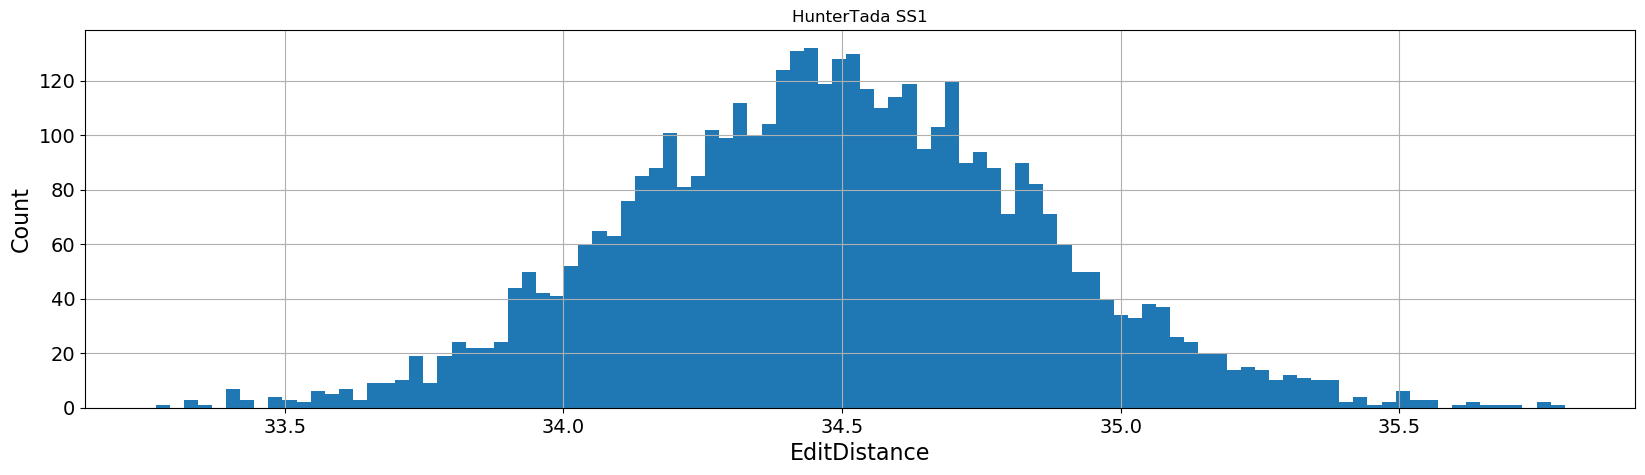

In [10]:
from matplotlib.pyplot import figure
plt.rcParams['figure.figsize'] = [20, 5]

SS1_HunterTada = pd.read_csv('SS1_HunterTada.csv')

N, bins, patches = plt.hist(SS1_HunterTada["Distance"], 100)

cmap = plt.get_cmap('jet')
high = cmap(0.3)
medium =cmap(0.2)
low = cmap(.95)

plt.grid()

#for i in range(0,35):
#    patches[i].set_facecolor(low)
#for i in range(35,100):
#    patches[i].set_facecolor(high)

plt.xlabel("EditDistance", fontsize=16)  
plt.ylabel("Count", fontsize=16)
plt.xticks(fontsize=14)  
plt.yticks(fontsize=14)
plt.title('HunterTada SS1')
plt.show()

In [6]:
SS1_HunterTadaTOP = SS1_HunterTada[SS1_HunterTada['Distance']>35]
len(SS1_HunterTadaTOP)

337

In [7]:
def levenshteinDistance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1

    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        distances_ = [i2+1]
        for i1, c1 in enumerate(s1):
            if c1 == c2:
                distances_.append(distances[i1])
            else:
                distances_.append(1 + min((distances[i1], distances[i1 + 1], distances_[-1])))
        distances = distances_
    return distances[-1]

finalholder = []
tempholder = 0
for x in SS1_HunterTadaTOP['Seq']:
    finalholder.append(np.mean(tempholder))
    tempholder = []
    for y in SS1_HunterTadaTOP['Seq']:
        tempholder.append(levenshteinDistance(x,y))
finalholder.append(np.mean(tempholder))
finalholder.pop(0)

SS1_HunterTadaTOP['Distance2'] = finalholder
SS1_HunterTadaTOP

/global/software/sl-7.x86_64/modules/langs/python/3.7/lib/python3.7/site-packages/ipykernel_launcher.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,Unnamed: 0,ADHunter Score,Seq,TADA Score,Distance,Distance2
10,10,158438.03,PVKKDYGSFQDYCFSLWPSSEWILDSFHNHGCNINNGFWR,0.607206,35.306578,35.560831
15,15,189447.50,MCELELDIFVSSLHPGTFFGWEPVCEEPYIHHTIEGECDN,0.609867,35.293238,35.486647
24,24,222640.12,PFGMDIIYEYDSFQMFETIFSSHLFDSPNSMTGGQMMCWG,0.659504,35.222631,35.433234
29,29,193151.34,TFSSSFHVYHALLNWYEIGMEEKTEPSIDEWLNDFFNMFE,0.659614,35.058878,35.308605
33,33,171712.94,SYPFEEFCFEMPDLCLENREISEEWAGRGYGISHYLEMEE,0.666588,35.263799,35.516320
...,...,...,...,...,...,...
4272,4272,187176.84,FNGNWPMDSFLSWAHQFYVTWEAKDSPSFAVEMEIVDMDF,0.644194,35.030359,35.109792
4279,4279,160082.16,NKYGQQTNTFVETQQFMESSWFWCLEEDMILEDNNYTMQP,0.632982,35.418583,35.448071
4284,4284,180678.42,VNHVDWDFMYCSSSCETSADGMFFDAIPCDQLTPLHMGHK,0.605116,35.385235,35.721068
4313,4313,179325.77,NDWEPQDITEGFWTADPRWFSGMSPTPPPHLAEYMEELFP,0.656618,35.216191,35.290801


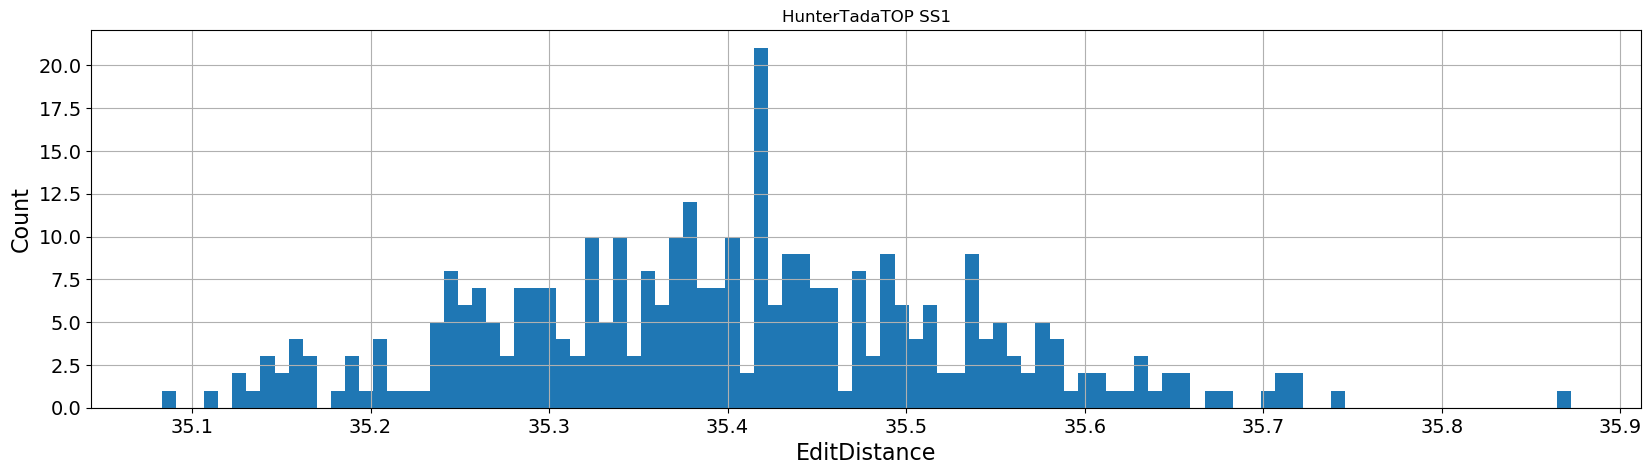

In [9]:
from matplotlib.pyplot import figure
plt.rcParams['figure.figsize'] = [20, 5]

N, bins, patches = plt.hist(SS1_HunterTadaTOP["Distance2"], 100)

cmap = plt.get_cmap('jet')
high = cmap(0.3)
medium =cmap(0.2)
low = cmap(.95)

plt.grid()

#for i in range(0,35):
#    patches[i].set_facecolor(low)
#for i in range(35,100):
#    patches[i].set_facecolor(high)

plt.xlabel("EditDistance", fontsize=16)  
plt.ylabel("Count", fontsize=16)
plt.xticks(fontsize=14)  
plt.yticks(fontsize=14)
plt.title('HunterTadaTOP SS1')
plt.show()

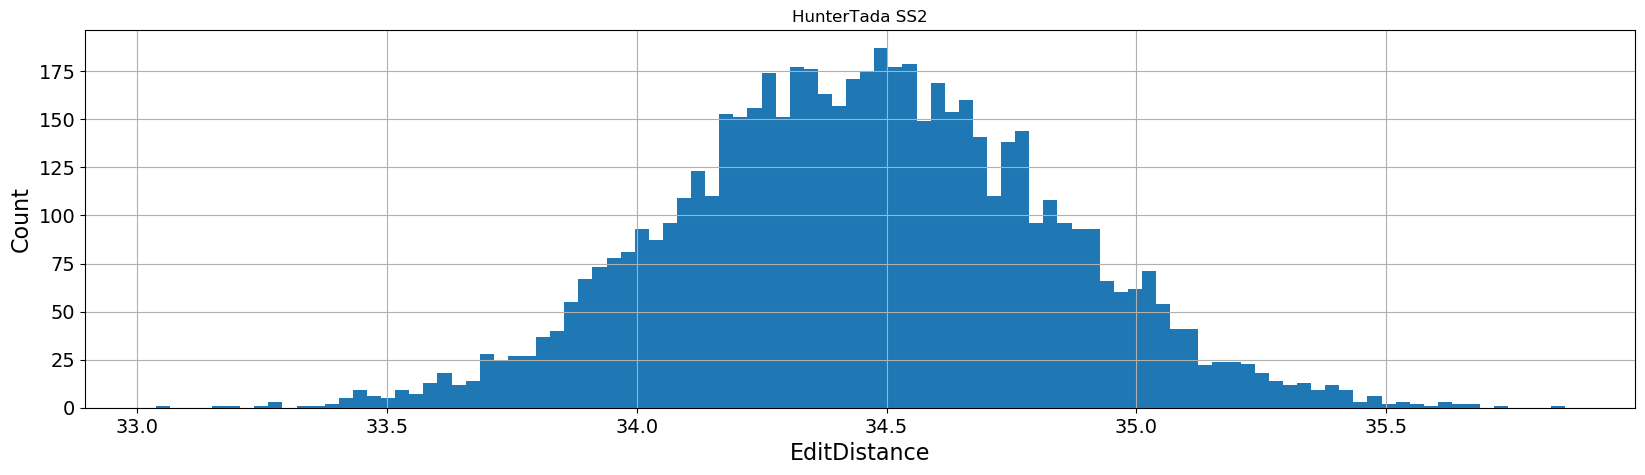

In [11]:
from matplotlib.pyplot import figure
plt.rcParams['figure.figsize'] = [20, 5]

SS2_HunterTada = pd.read_csv('SS2_HunterTada.csv')

N, bins, patches = plt.hist(SS2_HunterTada["Distance"], 100)

cmap = plt.get_cmap('jet')
high = cmap(0.3)
medium =cmap(0.2)
low = cmap(.95)

plt.grid()

#for i in range(0,35):
#    patches[i].set_facecolor(low)
#for i in range(35,100):
#    patches[i].set_facecolor(high)

plt.xlabel("EditDistance", fontsize=16)  
plt.ylabel("Count", fontsize=16)
plt.xticks(fontsize=14)  
plt.yticks(fontsize=14)
plt.title('HunterTada SS2')
plt.show()

In [12]:
SS2_HunterTadaTOP = SS2_HunterTada[SS2_HunterTada['Distance']>35]
print(len(SS2_HunterTadaTOP))

finalholder = []
tempholder = 0
for x in SS2_HunterTadaTOP['Seq']:
    finalholder.append(np.mean(tempholder))
    tempholder = []
    for y in SS2_HunterTadaTOP['Seq']:
        tempholder.append(levenshteinDistance(x,y))
finalholder.append(np.mean(tempholder))
finalholder.pop(0)

SS2_HunterTadaTOP['Distance2'] = finalholder
SS2_HunterTadaTOP

442


/global/software/sl-7.x86_64/modules/langs/python/3.7/lib/python3.7/site-packages/ipykernel_launcher.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,Unnamed: 0,ADHunter Score,Seq,TADA Score,Distance,Distance2
13,13,176605.90,SVAVSESVNGELERWECVETSYFNFSESVATTEQQNLFWW,0.616814,35.208731,35.262443
17,17,210900.00,MFDTMETFDFSTAATSGGGVDVDDCFLLFDTWQPPSHKPL,0.622377,35.013984,35.649321
39,39,160041.78,MLDEDEVQWDYMGHGRGLQGIGEGEDFFQEMMMNHEENFD,0.607994,35.197306,35.371041
52,52,188400.75,ENNNYIEQSQEITTHDDHVDIGVELLETDWDPDFFAMLLC,0.615019,35.020634,35.531674
55,55,151571.25,IECHIQEPWDEDGACALGFWPLTFDCSCFCKIGGDEIEEE,0.604049,35.247271,35.488688
...,...,...,...,...,...,...
5813,5813,172586.98,GSNSRFFTFLSHSECVIELQEHQGQWDFSNTDLMPWEMNM,0.620421,35.033765,35.328054
5838,5838,174545.40,SCYFSELSFEHTYNEFSIFYPTRGNYGCGDQIPPFFEDEI,0.628030,35.096351,35.201357
5846,5846,178645.17,ALITSVSPIYFFGSDDFFTNINPFTGTWAWEWVKEMFEDQ,0.649616,35.336289,35.466063
5851,5851,214269.12,MEFADLEGLDPDMMMMVLVSYEMEMFVPTGSPVPWEEAWE,0.673862,35.087483,35.296380


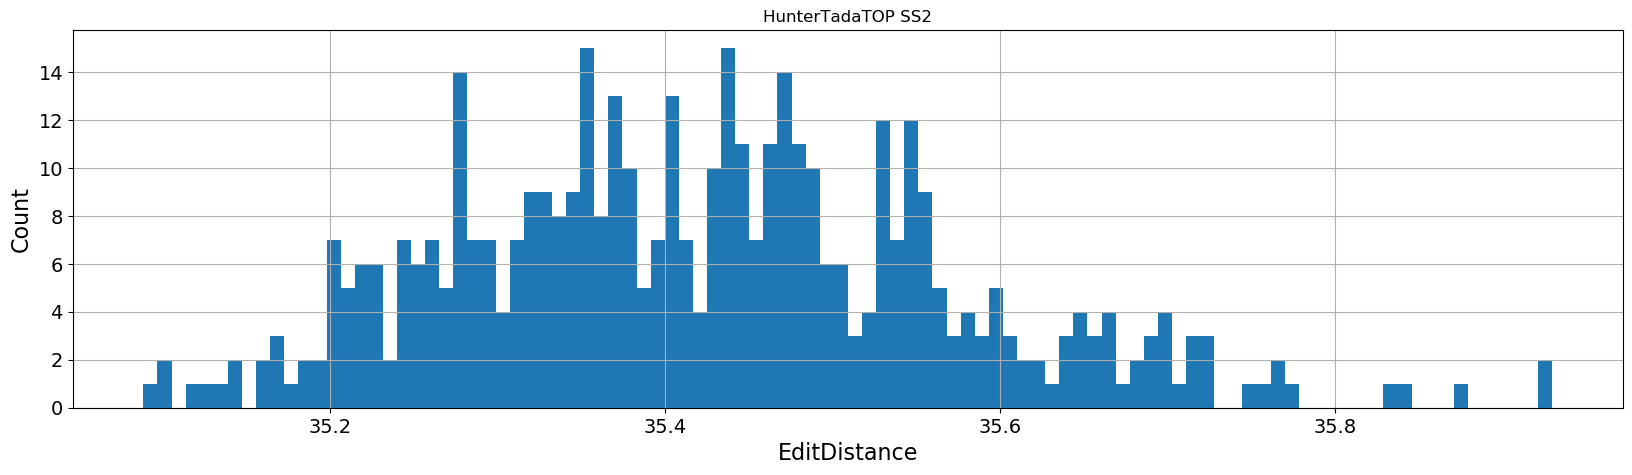

In [13]:
from matplotlib.pyplot import figure
plt.rcParams['figure.figsize'] = [20, 5]

N, bins, patches = plt.hist(SS2_HunterTadaTOP["Distance2"], 100)

cmap = plt.get_cmap('jet')
high = cmap(0.3)
medium =cmap(0.2)
low = cmap(.95)

plt.grid()

#for i in range(0,35):
#    patches[i].set_facecolor(low)
#for i in range(35,100):
#    patches[i].set_facecolor(high)

plt.xlabel("EditDistance", fontsize=16)  
plt.ylabel("Count", fontsize=16)
plt.xticks(fontsize=14)  
plt.yticks(fontsize=14)
plt.title('HunterTadaTOP SS2')
plt.show()

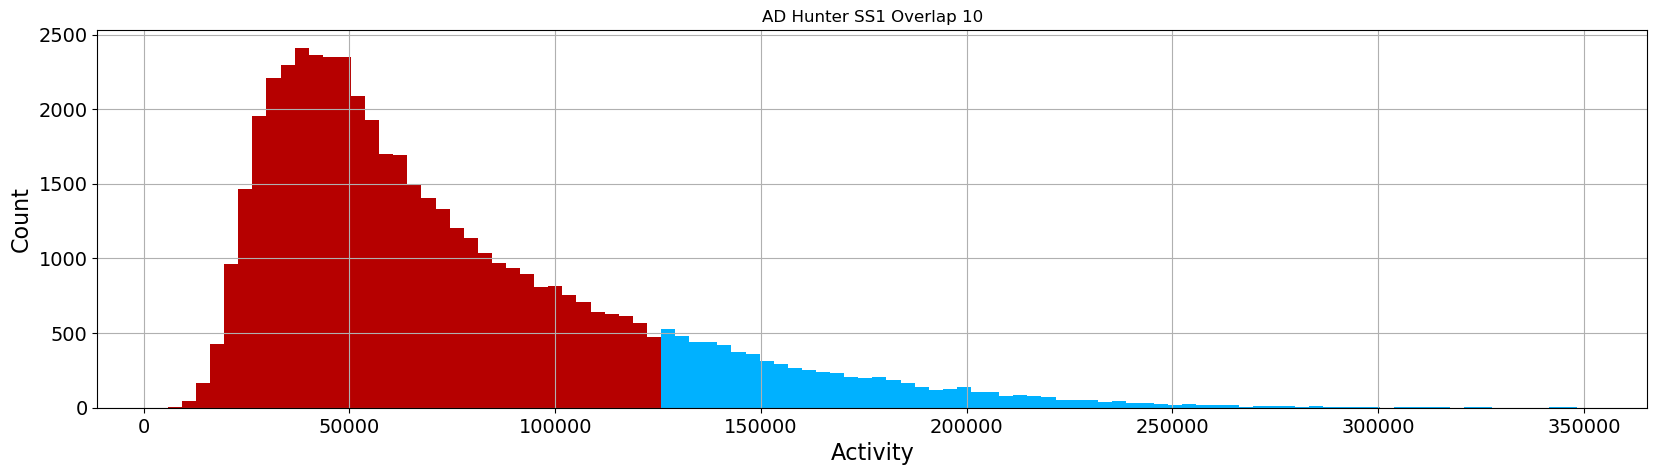

In [7]:
from matplotlib.pyplot import figure
plt.rcParams['figure.figsize'] = [20, 5]

ADHUNTER_SS1_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS1_10_overlap_ADHUNTER_PREDICTED.csv')

N, bins, patches = plt.hist(ADHUNTER_SS1_10["Score"], 100)

cmap = plt.get_cmap('jet')
high = cmap(0.3)
medium =cmap(0.2)
low = cmap(.95)

plt.grid()

for i in range(0,35):
    patches[i].set_facecolor(low)
for i in range(35,100):
    patches[i].set_facecolor(high)

plt.xlabel("Activity", fontsize=16)  
plt.ylabel("Count", fontsize=16)
plt.xticks(fontsize=14)  
plt.yticks(fontsize=14)
plt.title('AD Hunter SS1 Overlap 10')
plt.show()

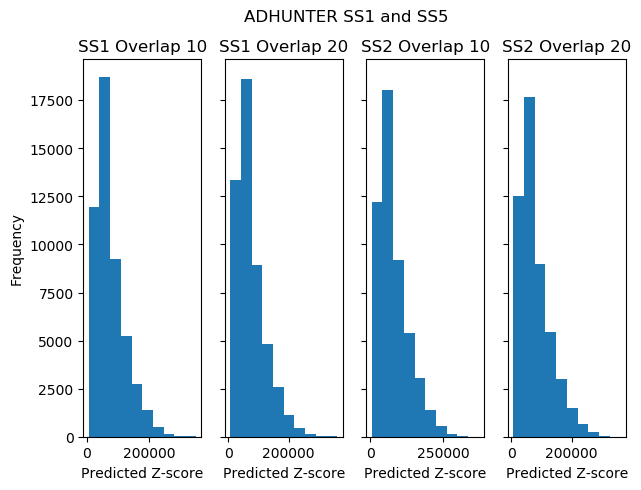

In [19]:
ADHUNTER_SS1_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS1_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
ADHUNTER_SS1_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS1_20_overlap_ADHUNTER_PREDICTED.csv')['Score']
ADHUNTER_SS2_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS2_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
ADHUNTER_SS2_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS2_20_overlap_ADHUNTER_PREDICTED.csv')['Score']


fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols = 4, sharey=True)
ax1.set_xlabel('Predicted Z-score')
ax2.set_xlabel('Predicted Z-score')
ax3.set_xlabel('Predicted Z-score')
ax4.set_xlabel('Predicted Z-score')
fig.suptitle('ADHUNTER SS1 and SS5')

ADHUNTER_SS1_10.plot(kind = 'hist',ax = ax1, figsize = (7,5), title = "SS1 Overlap 10")
ADHUNTER_SS1_20.plot(kind = 'hist',ax = ax2, figsize = (7,5), title = "SS1 Overlap 20")
ADHUNTER_SS2_10.plot(kind = 'hist',ax = ax3, figsize = (7,5), title = "SS2 Overlap 10")
ADHUNTER_SS2_20.plot(kind = 'hist',ax = ax4, figsize = (7,5), title = "SS2 Overlap 20")

plt.show()

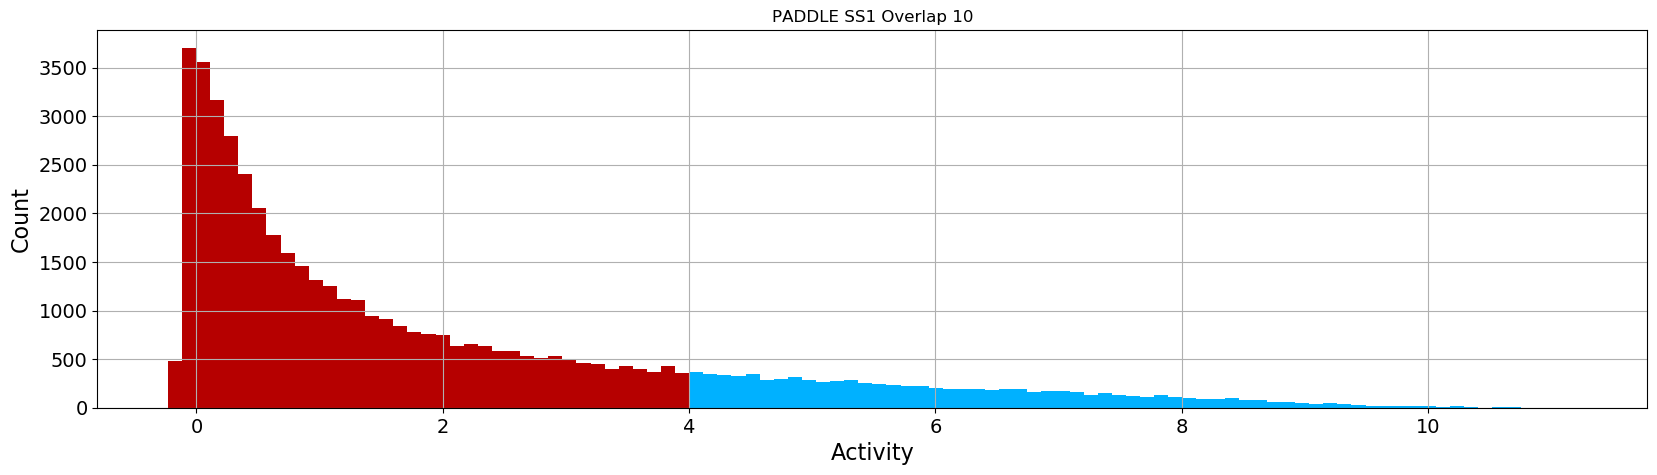

In [17]:
plt.rcParams['figure.figsize'] = [20, 5]

PADDLE_SS1_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS1_10_overlap_PADDLE_PREDICTED.csv')

N, bins, patches = plt.hist(PADDLE_SS1_10["0"], 100)

cmap = plt.get_cmap('jet')
high = cmap(0.3)
medium =cmap(0.2)
low = cmap(.95)

plt.grid()

for i in range(0,37):
    patches[i].set_facecolor(low)
for i in range(37,100):
    patches[i].set_facecolor(high)

plt.xlabel("Activity", fontsize=16)  
plt.ylabel("Count", fontsize=16)
plt.xticks(fontsize=14)  
plt.yticks(fontsize=14)
plt.title('PADDLE SS1 Overlap 10')
plt.show()

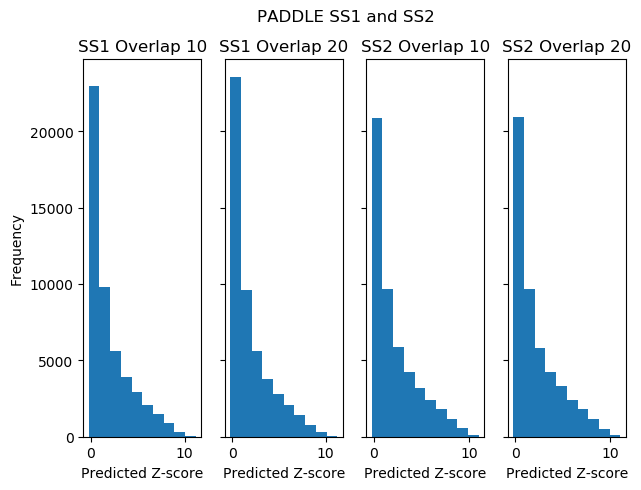

In [21]:
PADDLE_SS1_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS1_10_overlap_PADDLE_PREDICTED.csv')['0']
PADDLE_SS1_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS1_20_overlap_PADDLE_PREDICTED.csv')['0']
PADDLE_SS2_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS2_10_overlap_PADDLE_PREDICTED.csv')['0']
PADDLE_SS2_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS2_20_overlap_PADDLE_PREDICTED.csv')['0']

fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols = 4, sharey=True)
ax1.set_xlabel('Predicted Z-score')
ax2.set_xlabel('Predicted Z-score')
ax3.set_xlabel('Predicted Z-score')
ax4.set_xlabel('Predicted Z-score')

fig.suptitle('PADDLE SS1 and SS2')

PADDLE_SS1_10.plot(kind = 'hist',ax = ax1, figsize = (7,5), title = "SS1 Overlap 10")
PADDLE_SS1_20.plot(kind = 'hist',ax = ax2, figsize = (7,5), title = "SS1 Overlap 20")
PADDLE_SS2_10.plot(kind = 'hist',ax = ax3, figsize = (7,5), title = "SS2 Overlap 10")
PADDLE_SS2_20.plot(kind = 'hist',ax = ax4, figsize = (7,5), title = "SS2 Overlap 20")

plt.show()

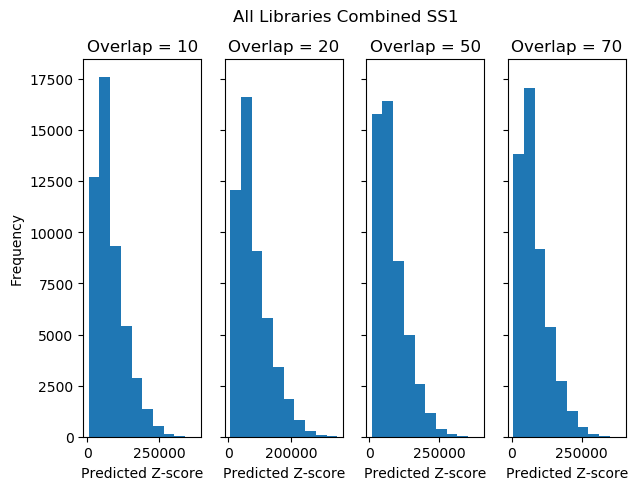

In [30]:
SS1_10_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS1_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS1_20_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS1_20_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS1_50_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS1_50_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS1_70_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS1_70_overlap_ADHUNTER_PREDICTED.csv')['Score']

fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols = 4, sharey=True)
ax1.set_xlabel('Predicted Z-score')
ax2.set_xlabel('Predicted Z-score')
ax3.set_xlabel('Predicted Z-score')
ax4.set_xlabel('Predicted Z-score')
fig.suptitle('All Libraries Combined SS1')

SS1_10_PREDICTED.plot(kind = 'hist',ax = ax1, figsize = (7,5), title = "Overlap = 10")
SS1_20_PREDICTED.plot(kind = 'hist',ax = ax2, figsize = (7,5), title = "Overlap = 20")
SS1_50_PREDICTED.plot(kind = 'hist',ax = ax3, figsize = (7,5), title = "Overlap = 50")
SS1_70_PREDICTED.plot(kind = 'hist',ax = ax4, figsize = (7,5), title = "Overlap = 70")

plt.show()

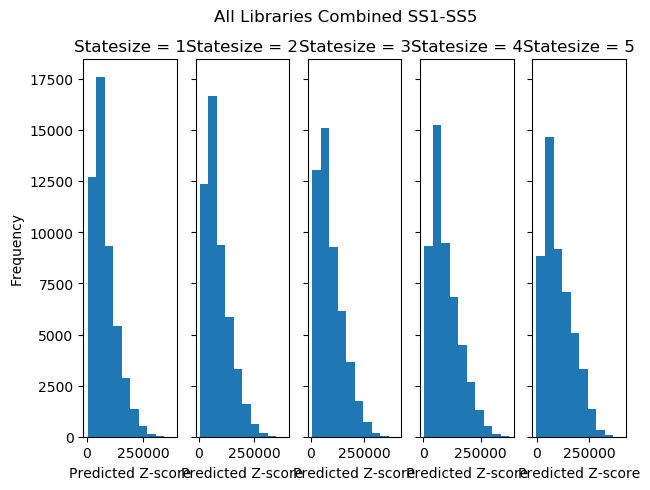

In [31]:
SS1_10_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS1_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS2_10_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS2_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS3_10_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS3_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS4_10_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS4_10_overlap_ADHUNTER_PREDICTED.csv')['Score']
SS5_10_PREDICTED = pd.read_csv('ADHunter_Predicted(V3)/SS5_10_overlap_ADHUNTER_PREDICTED.csv')['Score']

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(ncols = 5, sharey=True)
ax1.set_xlabel('Predicted Z-score')
ax2.set_xlabel('Predicted Z-score')
ax3.set_xlabel('Predicted Z-score')
ax4.set_xlabel('Predicted Z-score')
ax5.set_xlabel('Predicted Z-score')
fig.suptitle('All Libraries Combined SS1-SS5')

SS1_10_PREDICTED.plot(kind = 'hist',ax = ax1, figsize = (7,5), title = "Statesize = 1")
SS2_10_PREDICTED.plot(kind = 'hist',ax = ax2, figsize = (7,5), title = "Statesize = 2")
SS3_10_PREDICTED.plot(kind = 'hist',ax = ax3, figsize = (7,5), title = "Statesize = 3")
SS4_10_PREDICTED.plot(kind = 'hist',ax = ax4, figsize = (7,5), title = "Statesize = 4")
SS5_10_PREDICTED.plot(kind = 'hist',ax = ax5, figsize = (7,5), title = "Statesize = 5")

plt.show()

In [44]:
tester = pd.read_csv("Melvin_All_10_20_V2_preds.csv")
alignment = pd.read_csv('All_10_20_overlap_index.csv').reset_index()

KC_SS1_Overlap1020 = tester[(tester['GeneName'] < 100000)]
KC_SS1_Overlap1020 = np.array(KC_SS1_Overlap1020['GeneName'])
KC_SS1_Overlap1020 = alignment[alignment['level_0'].isin(KC_SS1_Overlap1020)].drop_duplicates(subset=['0'])
KC_SS1_Overlap1020.to_csv('KothaCompSS1.csv', index=False)

KC_SS2_Overlap1020 = tester[(tester['GeneName'] < 200000) & (tester['GeneName'] >= 100000)]
KC_SS2_Overlap1020 = np.array(KC_SS2_Overlap1020['GeneName'])
KC_SS2_Overlap1020 = alignment[alignment['level_0'].isin(KC_SS2_Overlap1020)].drop_duplicates(subset=['0'])
KC_SS2_Overlap1020.to_csv('KothaCompSS2.csv', index=False)

KC_SS3_Overlap1020 = tester[(tester['GeneName'] < 300000) & (tester['GeneName'] >= 200000)]
KC_SS3_Overlap1020 = np.array(KC_SS3_Overlap1020['GeneName'])
KC_SS3_Overlap1020 = alignment[alignment['level_0'].isin(KC_SS3_Overlap1020)].drop_duplicates(subset=['0'])
KC_SS3_Overlap1020.to_csv('KothaCompSS3.csv', index=False)

KC_SS4_Overlap1020 = tester[(tester['GeneName'] < 400000) & (tester['GeneName'] >= 300000)]
KC_SS4_Overlap1020 = np.array(KC_SS4_Overlap1020['GeneName'])
KC_SS4_Overlap1020 = alignment[alignment['level_0'].isin(KC_SS4_Overlap1020)].drop_duplicates(subset=['0'])
KC_SS4_Overlap1020.to_csv('KothaCompSS4.csv', index=False)

KC_SS5_Overlap1020 = tester[(tester['GeneName'] < 500000) & (tester['GeneName'] >= 400000)]
KC_SS5_Overlap1020 = np.array(KC_SS5_Overlap1020['GeneName'])
KC_SS5_Overlap1020 = alignment[alignment['level_0'].isin(KC_SS5_Overlap1020)].drop_duplicates(subset=['0'])
KC_SS5_Overlap1020.to_csv('KothaCompSS5.csv', index=False)


In [7]:
ADHUNTER_SS1_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS1_10_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS1_10['Origin'] = ['ADHUNTER_SS1_10']*len(ADHUNTER_SS1_10)
ADHUNTER_SS1_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS1_20_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS1_20['Origin'] = ['ADHUNTER_SS1_20']*len(ADHUNTER_SS1_10)
ADHUNTER_SS2_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS2_10_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS2_10['Origin'] = ['ADHUNTER_SS2_10']*len(ADHUNTER_SS1_10)
ADHUNTER_SS2_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS2_20_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS2_20['Origin'] = ['ADHUNTER_SS2_20']*len(ADHUNTER_SS1_10)
ADHUNTER_SS3_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS3_10_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS3_10['Origin'] = ['ADHUNTER_SS3_10']*len(ADHUNTER_SS1_10)
ADHUNTER_SS3_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS3_20_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS3_20['Origin'] = ['ADHUNTER_SS3_20']*len(ADHUNTER_SS1_10)
ADHUNTER_SS4_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS4_10_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS4_10['Origin'] = ['ADHUNTER_SS4_10']*len(ADHUNTER_SS1_10)
ADHUNTER_SS4_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS4_20_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS4_20['Origin'] = ['ADHUNTER_SS4_20']*len(ADHUNTER_SS1_10)
ADHUNTER_SS5_10 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS5_10_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS5_10['Origin'] = ['ADHUNTER_SS5_10']*len(ADHUNTER_SS1_10)
ADHUNTER_SS5_20 = pd.read_csv('/global/scratch/users/melvins/ADHUNTER/SS5_20_overlap_ADHUNTER_PREDICTED.csv')
ADHUNTER_SS5_20['Origin'] = ['ADHUNTER_SS5_20']*len(ADHUNTER_SS1_10)

PADDLE_SS1_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS1_10_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS1_10['Seq'] = ADHUNTER_SS1_10['Seq']
PADDLE_SS1_10['Origin'] = ['PADDLE_SS1_10']*len(PADDLE_SS1_10)
PADDLE_SS1_10 = PADDLE_SS1_10.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS1_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS1_20_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS1_20['Seq'] = ADHUNTER_SS1_20['Seq']
PADDLE_SS1_20['Origin'] = ['PADDLE_SS1_20']*len(PADDLE_SS1_20)
PADDLE_SS1_20 = PADDLE_SS1_20.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS2_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS2_10_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS2_10['Seq'] = ADHUNTER_SS2_10['Seq']
PADDLE_SS2_10['Origin'] = ['PADDLE_SS2_10']*len(PADDLE_SS2_10)
PADDLE_SS2_10 = PADDLE_SS2_10.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS2_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS2_20_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS2_20['Seq'] = ADHUNTER_SS2_20['Seq']
PADDLE_SS2_20['Origin'] = ['PADDLE_SS2_20']*len(PADDLE_SS2_20)
PADDLE_SS2_20 = PADDLE_SS2_20.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS3_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS3_10_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS3_10['Seq'] = ADHUNTER_SS3_10['Seq']
PADDLE_SS3_10['Origin'] = ['PADDLE_SS3_10']*len(PADDLE_SS3_10)
PADDLE_SS3_10 = PADDLE_SS3_10.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS3_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS3_20_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS3_20['Seq'] = ADHUNTER_SS3_20['Seq']
PADDLE_SS3_20['Origin'] = ['PADDLE_SS3_20']*len(PADDLE_SS3_20)
PADDLE_SS3_20 = PADDLE_SS3_20.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS4_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS4_10_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS4_10['Seq'] = ADHUNTER_SS4_10['Seq']
PADDLE_SS4_10['Origin'] = ['PADDLE_SS4_10']*len(PADDLE_SS4_10)
PADDLE_SS4_10 = PADDLE_SS4_10.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS4_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS4_20_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS4_20['Seq'] = ADHUNTER_SS4_20['Seq']
PADDLE_SS4_20['Origin'] = ['PADDLE_SS4_20']*len(PADDLE_SS4_20)
PADDLE_SS4_20 = PADDLE_SS4_20.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS5_10 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS5_10_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS5_10['Seq'] = ADHUNTER_SS5_10['Seq']
PADDLE_SS5_10['Origin'] = ['PADDLE_SS5_10']*len(PADDLE_SS5_10)
PADDLE_SS5_10 = PADDLE_SS5_10.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])
PADDLE_SS5_20 = pd.read_csv('/global/scratch/users/melvins/PADDLE/SS5_20_overlap_PADDLE_PREDICTED.csv')
PADDLE_SS5_20['Seq'] = ADHUNTER_SS5_20['Seq']
PADDLE_SS5_20['Origin'] = ['PADDLE_SS5_20']*len(PADDLE_SS5_20)
PADDLE_SS5_20 = PADDLE_SS5_20.rename(columns={'0':'Score'}).drop(columns=['Unnamed: 0'])

All_TADA_Predictions = pd.read_csv('/global/scratch/users/melvins/TADA/TADA_Predictions.csv')
All_TADA_Predictions['Origin'] = ['TADA_SS1_10']*50000+['TADA_SS1_20']*50000+['TADA_SS2_10']*50000+['TADA_SS2_20']*50000+['TADA_SS3_10']*50000+['TADA_SS3_20']*50000+['TADA_SS4_10']*50000+['TADA_SS4_20']*50000+['TADA_SS5_10']*50000+['TADA_SS5_20']*50000
All_TADA_Predictions = All_TADA_Predictions.rename(columns={'sequences':'Seq','predictions':'Score'}).drop(columns=['Unnamed: 0','labels'])

result = pd.concat([PADDLE_SS1_10,PADDLE_SS1_20,
                    PADDLE_SS2_10,PADDLE_SS2_20,
                    PADDLE_SS3_10,PADDLE_SS3_20,
                    PADDLE_SS4_10,PADDLE_SS4_20,
                    PADDLE_SS5_10,PADDLE_SS5_20,
                    ADHUNTER_SS1_10,ADHUNTER_SS1_20,
                    ADHUNTER_SS2_10,ADHUNTER_SS2_20,
                    ADHUNTER_SS3_10,ADHUNTER_SS3_20,
                    ADHUNTER_SS4_10,ADHUNTER_SS4_20,
                    ADHUNTER_SS5_10,ADHUNTER_SS5_20,
                    All_TADA_Predictions])
result.to_csv('ADhunter_Paddle_TADA_AllPredictions',index=False)


In [4]:
df = pd.read_csv('ADhunter_Paddle_TADA_AllPredictions')

In [50]:
PaddleSS1 = df[(df['Origin'] == 'PADDLE_SS1_10')|(df['Origin'] == 'PADDLE_SS1_20')]
PaddleSS1 = PaddleSS1[PaddleSS1['Score'] >= 6]
PaddleSS1 = PaddleSS1.drop_duplicates(subset=['Seq'])
PaddleSS1.to_csv('PaddleSS1.csv',index=False)
PaddleSS2 = df[(df['Origin'] == 'PADDLE_SS2_10')|(df['Origin'] == 'PADDLE_SS2_20')]
PaddleSS2 = PaddleSS2[PaddleSS2['Score'] >= 6]
PaddleSS2 = PaddleSS2.drop_duplicates(subset=['Seq'])
PaddleSS2.to_csv('PaddleSS2.csv',index=False)
PaddleSS3 = df[(df['Origin'] == 'PADDLE_SS3_10')|(df['Origin'] == 'PADDLE_SS3_20')]
PaddleSS3 = PaddleSS3[PaddleSS3['Score'] >= 6]
PaddleSS3 = PaddleSS3.drop_duplicates(subset=['Seq'])
PaddleSS3.to_csv('PaddleSS3.csv',index=False)
PaddleSS4 = df[(df['Origin'] == 'PADDLE_SS4_10')|(df['Origin'] == 'PADDLE_SS4_20')]
PaddleSS4 = PaddleSS4[PaddleSS4['Score'] >= 6]
PaddleSS4 = PaddleSS4.drop_duplicates(subset=['Seq'])
PaddleSS4.to_csv('PaddleSS4.csv',index=False)
PaddleSS5 = df[(df['Origin'] == 'PADDLE_SS5_10')|(df['Origin'] == 'PADDLE_SS5_20')]
PaddleSS5 = PaddleSS5[PaddleSS5['Score'] >= 6]
PaddleSS5 = PaddleSS5.drop_duplicates(subset=['Seq'])
PaddleSS5.to_csv('PaddleSS5.csv',index=False)

HunterSS1 = df[(df['Origin'] == 'ADHUNTER_SS1_10')|(df['Origin'] == 'ADHUNTER_SS1_20')]
HunterSS1 = HunterSS1[HunterSS1['Score'] >= 150000]
HunterSS1 = HunterSS1.drop_duplicates(subset=['Seq'])
HunterSS1.to_csv('HunterSS1.csv',index=False)
HunterSS2 = df[(df['Origin'] == 'ADHUNTER_SS2_10')|(df['Origin'] == 'ADHUNTER_SS2_20')]
HunterSS2 = HunterSS2[HunterSS2['Score'] >= 150000]
HunterSS2 = HunterSS2.drop_duplicates(subset=['Seq'])
HunterSS2.to_csv('HunterSS2.csv',index=False)
HunterSS3 = df[(df['Origin'] == 'ADHUNTER_SS3_10')|(df['Origin'] == 'ADHUNTER_SS3_20')]
HunterSS3 = HunterSS3[HunterSS3['Score'] >= 150000]
HunterSS3 = HunterSS3.drop_duplicates(subset=['Seq'])
HunterSS3.to_csv('HunterSS3.csv',index=False)
HunterSS4 = df[(df['Origin'] == 'ADHUNTER_SS4_10')|(df['Origin'] == 'ADHUNTER_SS4_20')]
HunterSS4 = HunterSS4[HunterSS4['Score'] >= 150000]
HunterSS4 = HunterSS4.drop_duplicates(subset=['Seq'])
HunterSS4.to_csv('HunterSS4.csv',index=False)
HunterSS5 = df[(df['Origin'] == 'ADHUNTER_SS5_10')|(df['Origin'] == 'ADHUNTER_SS5_20')]
HunterSS5 = HunterSS5[HunterSS5['Score'] >= 150000]
HunterSS5 = HunterSS5.drop_duplicates(subset=['Seq'])
HunterSS5.to_csv('HunterSS5.csv',index=False)

TadaSS1 = df[(df['Origin'] == 'TADA_SS1_10')|(df['Origin'] == 'TADA_SS1_20')]
TadaSS1 = TadaSS1[TadaSS1['Score'] >= 0.6]
TadaSS1 = TadaSS1.drop_duplicates(subset=['Seq'])
TadaSS1.to_csv('TadaSS1.csv',index=False)
TadaSS2 = df[(df['Origin'] == 'TADA_SS2_10')|(df['Origin'] == 'TADA_SS2_20')]
TadaSS2 = TadaSS2[TadaSS2['Score'] >= 0.6]
TadaSS2 = TadaSS2.drop_duplicates(subset=['Seq'])
TadaSS2.to_csv('TadaSS2.csv',index=False)
TadaSS3 = df[(df['Origin'] == 'TADA_SS3_10')|(df['Origin'] == 'TADA_SS3_20')]
TadaSS3 = TadaSS3[TadaSS3['Score'] >= 0.6]
TadaSS3 = TadaSS3.drop_duplicates(subset=['Seq'])
TadaSS3.to_csv('TadaSS3.csv',index=False)
TadaSS4 = df[(df['Origin'] == 'TADA_SS4_10')|(df['Origin'] == 'TADA_SS4_20')]
TadaSS4 = TadaSS4[TadaSS4['Score'] >= 0.6]
TadaSS4 = TadaSS4.drop_duplicates(subset=['Seq'])
TadaSS4.to_csv('TadaSS4.csv',index=False)
TadaSS5 = df[(df['Origin'] == 'TADA_SS5_10')|(df['Origin'] == 'TADA_SS5_20')]
TadaSS5 = TadaSS5[TadaSS5['Score'] >= 0.6]
TadaSS5 = TadaSS5.drop_duplicates(subset=['Seq'])
TadaSS5.to_csv('TadaSS5.csv',index=False)

In [59]:
#This 4C2 = 6 «Hunter Tada – Hunter Paddle – Tada Paddle – Tada KC – Paddle KC – Hunter KC
SS1_HunterTada = HunterSS1.merge(TadaSS1, on = 'Seq', how = 'inner')
SS1_HunterTada = SS1_HunterTada.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS1_HunterTada.to_csv('HunterTadaSS1.csv', index = True)
SS2_HunterTada = HunterSS2.merge(TadaSS2, on = 'Seq', how = 'inner')
SS2_HunterTada = SS2_HunterTada.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS2_HunterTada.to_csv('HunterTadaSS2.csv', index = True)
SS3_HunterTada = HunterSS3.merge(TadaSS3, on = 'Seq', how = 'inner')
SS3_HunterTada = SS3_HunterTada.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS3_HunterTada.to_csv('HunterTadaSS3.csv', index = True)
SS4_HunterTada = HunterSS4.merge(TadaSS4, on = 'Seq', how = 'inner')
SS4_HunterTada = SS4_HunterTada.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS4_HunterTada.to_csv('HunterTadaSS4.csv', index = True)
SS5_HunterTada = HunterSS5.merge(TadaSS5, on = 'Seq', how = 'inner')
SS5_HunterTada = SS5_HunterTada.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS5_HunterTada.to_csv('HunterTadaSS5.csv', index = True)

SS1_PaddleHunter = PaddleSS1.merge(HunterSS1, on = 'Seq', how = 'inner')
SS1_PaddleHunter = SS1_PaddleHunter.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score'}).drop(columns = ['Origin_x','Origin_y'])
SS1_PaddleHunter.to_csv('HunterPaddleSS1.csv', index = True)
SS2_PaddleHunter = PaddleSS2.merge(HunterSS2, on = 'Seq', how = 'inner')
SS2_PaddleHunter = SS2_PaddleHunter.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score'}).drop(columns = ['Origin_x','Origin_y'])
SS2_PaddleHunter.to_csv('HunterPaddleSS2.csv', index = True)
SS3_PaddleHunter = PaddleSS3.merge(HunterSS3, on = 'Seq', how = 'inner')
SS3_PaddleHunter = SS3_PaddleHunter.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score'}).drop(columns = ['Origin_x','Origin_y'])
SS3_PaddleHunter.to_csv('HunterPaddleSS3.csv', index = True)
SS4_PaddleHunter = PaddleSS4.merge(HunterSS4, on = 'Seq', how = 'inner')
SS4_PaddleHunter = SS4_PaddleHunter.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score'}).drop(columns = ['Origin_x','Origin_y'])
SS4_PaddleHunter.to_csv('HunterPaddleSS4.csv', index = True)
SS5_PaddleHunter = PaddleSS5.merge(HunterSS5, on = 'Seq', how = 'inner')
SS5_PaddleHunter = SS5_PaddleHunter.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score'}).drop(columns = ['Origin_x','Origin_y'])
SS5_PaddleHunter.to_csv('HunterPaddleSS5.csv', index = True)

SS1_PaddleTada = PaddleSS1.merge(TadaSS1, on = 'Seq', how = 'inner')
SS1_PaddleTada = SS1_PaddleTada.rename(columns={'Score_x':'PADDLE Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS1_PaddleTada.to_csv('TadaPaddleSS1.csv', index = True)
SS2_PaddleTada = PaddleSS2.merge(TadaSS2, on = 'Seq', how = 'inner')
SS2_PaddleTada = SS2_PaddleTada.rename(columns={'Score_x':'PADDLE Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS2_PaddleTada.to_csv('TadaPaddleSS2.csv', index = True)
SS3_PaddleTada = PaddleSS3.merge(TadaSS3, on = 'Seq', how = 'inner')
SS3_PaddleTada = SS3_PaddleTada.rename(columns={'Score_x':'PADDLE Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS3_PaddleTada.to_csv('TadaPaddleSS3.csv', index = True)
SS4_PaddleTada = PaddleSS4.merge(TadaSS4, on = 'Seq', how = 'inner')
SS4_PaddleTada = SS4_PaddleTada.rename(columns={'Score_x':'PADDLE Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS4_PaddleTada.to_csv('TadaPaddleSS4.csv', index = True)
SS5_PaddleTada = PaddleSS5.merge(TadaSS5, on = 'Seq', how = 'inner')
SS5_PaddleTada = SS5_PaddleTada.rename(columns={'Score_x':'PADDLE Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y'])
SS5_PaddleTada.to_csv('TadaPaddleSS5.csv', index = True)

TadaKCSS1 = TadaSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaKCSS1 = TadaKCSS1.drop(columns = ['0','level_0', 'index'])
TadaKCSS1.to_csv('TadaKothaCompSS1.csv', index = True)
TadaKCSS2 = TadaSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaKCSS2 = TadaKCSS2.drop(columns = ['0','level_0', 'index'])
TadaKCSS2.to_csv('TadaKothaCompSS2.csv', index = True)
TadaKCSS3 = TadaSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaKCSS3 = TadaKCSS3.drop(columns = ['0','level_0', 'index'])
TadaKCSS3.to_csv('TadaKothaCompSS3.csv', index = True)
TadaKCSS4 = TadaSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaKCSS4 = TadaKCSS4.drop(columns = ['0','level_0', 'index'])
TadaKCSS4.to_csv('TadaKothaCompSS4.csv', index = True)
TadaKCSS5 = TadaSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaKCSS5 = TadaKCSS5.drop(columns = ['0','level_0', 'index'])
TadaKCSS5.to_csv('TadaKothaCompSS5.csv', index = True)

PaddleKCSS1 = PaddleSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
PaddleKCSS1 = PaddleKCSS1.drop(columns = ['0','level_0', 'index'])
PaddleKCSS1.to_csv('PaddleKothaCompSS1.csv', index = True)
PaddleKCSS2 = PaddleSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
PaddleKCSS2 = PaddleKCSS2.drop(columns = ['0','level_0', 'index'])
PaddleKCSS2.to_csv('PaddleKothaCompSS2.csv', index = True)
PaddleKCSS3 = PaddleSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
PaddleKCSS3 = PaddleKCSS3.drop(columns = ['0','level_0', 'index'])
PaddleKCSS3.to_csv('PaddleKothaCompSS3.csv', index = True)
PaddleKCSS4 = PaddleSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
PaddleKCSS4 = PaddleKCSS4.drop(columns = ['0','level_0', 'index'])
PaddleKCSS4.to_csv('PaddleKothaCompSS4.csv', index = True)
PaddleKCSS5 = PaddleSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
PaddleKCSS5 = PaddleKCSS5.drop(columns = ['0','level_0', 'index'])
PaddleKCSS5.to_csv('PaddleKothaCompSS5.csv', index = True)

HunterKCSS1 = HunterSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterKCSS1 = HunterKCSS1.drop(columns = ['0','level_0', 'index'])
HunterKCSS1.to_csv('HunterKothaCompSS1.csv', index = True)
HunterKCSS2 = HunterSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterKCSS2 = HunterKCSS2.drop(columns = ['0','level_0', 'index'])
HunterKCSS2.to_csv('HunterKothaCompSS2.csv', index = True)
HunterKCSS3 = HunterSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterKCSS3 = HunterKCSS3.drop(columns = ['0','level_0', 'index'])
HunterKCSS3.to_csv('HunterKothaCompSS3.csv', index = True)
HunterKCSS4 = HunterSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterKCSS4 = HunterKCSS4.drop(columns = ['0','level_0', 'index'])
HunterKCSS4.to_csv('HunterKothaCompSS4.csv', index = True)
HunterKCSS5 = HunterSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterKCSS5 = HunterKCSS5.drop(columns = ['0','level_0', 'index'])
HunterKCSS5.to_csv('HunterKothaCompSS5.csv', index = True)

#temp = TopPaddle.merge(TopADHunter, on = 'Seq', how = 'inner')
#temp = temp.merge(TopTADA, on = 'Seq', how = 'inner')
#temp = temp.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score','Score':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','Origin'])


In [73]:
#4C3 = 4 «Hunter Tada Paddle – Hunter Tada KC – Hunter Paddle KC – Tada Paddle KC

HunterTadaPaddleSS1 = PaddleSS1.merge(HunterSS1, on = 'Seq', how = 'inner')
HunterTadaPaddleSS1 = HunterTadaPaddleSS1.merge(TadaSS1, on = 'Seq', how = 'inner')
HunterTadaPaddleSS1 = HunterTadaPaddleSS1.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score','Score':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','Origin'])
HunterTadaPaddleSS1.to_csv('HunterTadaPaddleSS1.csv', index = True)
HunterTadaPaddleSS2 = PaddleSS2.merge(HunterSS2, on = 'Seq', how = 'inner')
HunterTadaPaddleSS2 = HunterTadaPaddleSS2.merge(TadaSS2, on = 'Seq', how = 'inner')
HunterTadaPaddleSS2 = HunterTadaPaddleSS2.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score','Score':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','Origin'])
HunterTadaPaddleSS2.to_csv('HunterTadaPaddleSS2.csv', index = True)
HunterTadaPaddleSS3 = PaddleSS3.merge(HunterSS3, on = 'Seq', how = 'inner')
HunterTadaPaddleSS3 = HunterTadaPaddleSS3.merge(TadaSS3, on = 'Seq', how = 'inner')
HunterTadaPaddleSS3 = HunterTadaPaddleSS3.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score','Score':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','Origin'])
HunterTadaPaddleSS3.to_csv('HunterTadaPaddleSS3.csv', index = True)
HunterTadaPaddleSS4 = PaddleSS4.merge(HunterSS4, on = 'Seq', how = 'inner')
HunterTadaPaddleSS4 = HunterTadaPaddleSS4.merge(TadaSS4, on = 'Seq', how = 'inner')
HunterTadaPaddleSS4 = HunterTadaPaddleSS4.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score','Score':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','Origin'])
HunterTadaPaddleSS4.to_csv('HunterTadaPaddleSS4.csv', index = True)
HunterTadaPaddleSS5 = PaddleSS5.merge(HunterSS5, on = 'Seq', how = 'inner')
HunterTadaPaddleSS5 = HunterTadaPaddleSS5.merge(TadaSS5, on = 'Seq', how = 'inner')
HunterTadaPaddleSS5 = HunterTadaPaddleSS5.rename(columns={'Score_x':'PADDLE Score','Score_y':'ADHunter Score','Score':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','Origin'])
HunterTadaPaddleSS5.to_csv('HunterTadaPaddleSS5.csv', index = True)

HunterTadaKothaCompSS1 = HunterSS1.merge(TadaSS1, on = 'Seq', how = 'inner')
HunterTadaKothaCompSS1 = HunterTadaKothaCompSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaKothaCompSS1 = HunterTadaKothaCompSS1.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterTadaKothaCompSS1.to_csv('HunterTadaKothaCompSS1.csv', index = True)
HunterTadaKothaCompSS2 = HunterSS2.merge(TadaSS2, on = 'Seq', how = 'inner')
HunterTadaKothaCompSS2 = HunterTadaKothaCompSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaKothaCompSS2 = HunterTadaKothaCompSS2.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterTadaKothaCompSS2.to_csv('HunterTadaKothaCompSS2.csv', index = True)
HunterTadaKothaCompSS3 = HunterSS3.merge(TadaSS3, on = 'Seq', how = 'inner')
HunterTadaKothaCompSS3 = HunterTadaKothaCompSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaKothaCompSS3 = HunterTadaKothaCompSS3.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterTadaKothaCompSS3.to_csv('HunterTadaKothaCompSS3.csv', index = True)
HunterTadaKothaCompSS4 = HunterSS4.merge(TadaSS4, on = 'Seq', how = 'inner')
HunterTadaKothaCompSS4 = HunterTadaKothaCompSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaKothaCompSS4 = HunterTadaKothaCompSS4.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterTadaKothaCompSS4.to_csv('HunterTadaKothaCompSS4.csv', index = True)
HunterTadaKothaCompSS5 = HunterSS5.merge(TadaSS5, on = 'Seq', how = 'inner')
HunterTadaKothaCompSS5 = HunterTadaKothaCompSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaKothaCompSS5 = HunterTadaKothaCompSS5.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterTadaKothaCompSS5.to_csv('HunterTadaKothaCompSS5.csv', index = True)

HunterPaddleKothaCompSS1 = HunterSS1.merge(PaddleSS1, on = 'Seq', how = 'inner')
HunterPaddleKothaCompSS1 = HunterPaddleKothaCompSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterPaddleKothaCompSS1 = HunterPaddleKothaCompSS1.rename(columns={'Score_x':'ADHunter Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterPaddleKothaCompSS1.to_csv('HunterPaddleKothaCompSS1.csv', index = True)
HunterPaddleKothaCompSS2 = HunterSS2.merge(PaddleSS2, on = 'Seq', how = 'inner')
HunterPaddleKothaCompSS2 = HunterPaddleKothaCompSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterPaddleKothaCompSS2 = HunterPaddleKothaCompSS2.rename(columns={'Score_x':'ADHunter Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterPaddleKothaCompSS2.to_csv('HunterPaddleKothaCompSS2.csv', index = True)
HunterPaddleKothaCompSS3 = HunterSS3.merge(PaddleSS3, on = 'Seq', how = 'inner')
HunterPaddleKothaCompSS3 = HunterPaddleKothaCompSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterPaddleKothaCompSS3 = HunterPaddleKothaCompSS3.rename(columns={'Score_x':'ADHunter Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterPaddleKothaCompSS3.to_csv('HunterPaddleKothaCompSS3.csv', index = True)
HunterPaddleKothaCompSS4 = HunterSS4.merge(PaddleSS4, on = 'Seq', how = 'inner')
HunterPaddleKothaCompSS4 = HunterPaddleKothaCompSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterPaddleKothaCompSS4 = HunterPaddleKothaCompSS4.rename(columns={'Score_x':'ADHunter Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterPaddleKothaCompSS4.to_csv('HunterPaddleKothaCompSS4.csv', index = True)
HunterPaddleKothaCompSS5 = HunterSS5.merge(PaddleSS5, on = 'Seq', how = 'inner')
HunterPaddleKothaCompSS5 = HunterPaddleKothaCompSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterPaddleKothaCompSS5 = HunterPaddleKothaCompSS5.rename(columns={'Score_x':'ADHunter Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
HunterPaddleKothaCompSS5.to_csv('HunterPaddleKothaCompSS5.csv', index = True)

TadaPaddleKothaCompSS1 = TadaSS1.merge(PaddleSS1, on = 'Seq', how = 'inner')
TadaPaddleKothaCompSS1 = TadaPaddleKothaCompSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaPaddleKothaCompSS1 = TadaPaddleKothaCompSS1.rename(columns={'Score_x':'TADA Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
TadaPaddleKothaCompSS1.to_csv('TadaPaddleKothaCompSS1.csv', index = True)
TadaPaddleKothaCompSS2 = TadaSS2.merge(PaddleSS2, on = 'Seq', how = 'inner')
TadaPaddleKothaCompSS2 = TadaPaddleKothaCompSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaPaddleKothaCompSS2 = TadaPaddleKothaCompSS2.rename(columns={'Score_x':'TADA Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
TadaPaddleKothaCompSS2.to_csv('TadaPaddleKothaCompSS2.csv', index = True)
TadaPaddleKothaCompSS3 = TadaSS3.merge(PaddleSS3, on = 'Seq', how = 'inner')
TadaPaddleKothaCompSS3 = TadaPaddleKothaCompSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaPaddleKothaCompSS3 = TadaPaddleKothaCompSS3.rename(columns={'Score_x':'TADA Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
TadaPaddleKothaCompSS3.to_csv('TadaPaddleKothaCompSS3.csv', index = True)
TadaPaddleKothaCompSS4 = TadaSS4.merge(PaddleSS4, on = 'Seq', how = 'inner')
TadaPaddleKothaCompSS4 = TadaPaddleKothaCompSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaPaddleKothaCompSS4 = TadaPaddleKothaCompSS4.rename(columns={'Score_x':'TADA Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
TadaPaddleKothaCompSS4.to_csv('TadaPaddleKothaCompSS4.csv', index = True)
TadaPaddleKothaCompSS5 = TadaSS5.merge(PaddleSS5, on = 'Seq', how = 'inner')
TadaPaddleKothaCompSS5 = TadaPaddleKothaCompSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
TadaPaddleKothaCompSS5 = TadaPaddleKothaCompSS5.rename(columns={'Score_x':'TADA Score','Score_y':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','index','level_0','0'])
TadaPaddleKothaCompSS5.to_csv('TadaPaddleKothaCompSS5.csv', index = True)


In [74]:
#4C3 = 1 «Hunter Tada Paddle KC

HunterTadaPaddleKothaCompSS1 = HunterSS1.merge(TadaSS1, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS1 = HunterTadaPaddleKothaCompSS1.merge(PaddleSS1, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS1 = HunterTadaPaddleKothaCompSS1.merge(KC_SS1_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaPaddleKothaCompSS1 = HunterTadaPaddleKothaCompSS1.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score','Score':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','Origin','index','level_0','0'])
HunterTadaPaddleKothaCompSS1.to_csv('HunterTadaPaddleKothaCompSS1.csv', index = True)
HunterTadaPaddleKothaCompSS2 = HunterSS2.merge(TadaSS2, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS2 = HunterTadaPaddleKothaCompSS2.merge(PaddleSS2, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS2 = HunterTadaPaddleKothaCompSS2.merge(KC_SS2_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaPaddleKothaCompSS2 = HunterTadaPaddleKothaCompSS2.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score','Score':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','Origin','index','level_0','0'])
HunterTadaPaddleKothaCompSS2.to_csv('HunterTadaPaddleKothaCompSS2.csv', index = True)
HunterTadaPaddleKothaCompSS3 = HunterSS3.merge(TadaSS3, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS3 = HunterTadaPaddleKothaCompSS3.merge(PaddleSS3, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS3 = HunterTadaPaddleKothaCompSS3.merge(KC_SS3_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaPaddleKothaCompSS3 = HunterTadaPaddleKothaCompSS3.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score','Score':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','Origin','index','level_0','0'])
HunterTadaPaddleKothaCompSS3.to_csv('HunterTadaPaddleKothaCompSS3.csv', index = True)
HunterTadaPaddleKothaCompSS4 = HunterSS4.merge(TadaSS4, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS4 = HunterTadaPaddleKothaCompSS4.merge(PaddleSS4, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS4 = HunterTadaPaddleKothaCompSS4.merge(KC_SS4_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaPaddleKothaCompSS4 = HunterTadaPaddleKothaCompSS4.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score','Score':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','Origin','index','level_0','0'])
HunterTadaPaddleKothaCompSS4.to_csv('HunterTadaPaddleKothaCompSS4.csv', index = True)
HunterTadaPaddleKothaCompSS5 = HunterSS5.merge(TadaSS5, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS5 = HunterTadaPaddleKothaCompSS5.merge(PaddleSS5, on = 'Seq', how = 'inner')
HunterTadaPaddleKothaCompSS5 = HunterTadaPaddleKothaCompSS5.merge(KC_SS5_Overlap1020, left_on = 'Seq', right_on = '0', how = 'inner')
HunterTadaPaddleKothaCompSS5 = HunterTadaPaddleKothaCompSS5.rename(columns={'Score_x':'ADHunter Score','Score_y':'TADA Score','Score':'PADDLE Score'}).drop(columns = ['Origin_x','Origin_y','Origin','index','level_0','0'])
HunterTadaPaddleKothaCompSS5.to_csv('HunterTadaPaddleKothaCompSS5.csv', index = True)

